# Неделя 18. Практика Deep Learning и принципы LLM

**Практикум · Tech Orda · Gizatov A. S.**

Два занятия по 90 минут: 72 минуты теории и 108 минут практики за неделю.
Выполняйте ячейки последовательно через **Restart Kernel → Run All**.
Все обязательные вычисления работают на CPU без сети и API-ключей.

**Результат:** обучить небольшую нейросеть, выбрать регуляризацию по validation, один раз оценить test; вручную вычислить causal self-attention.

**Граница демонстрации:** MLP действительно обучается. Attention ниже использует случайные учебные матрицы и не является обученной LLM.


In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Работает из корня репозитория, папки недели и подпапок practice/homework.
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents] if (p / "course_plan.json").exists())
WEEK = ROOT / "week_18_dl_llm_intro"
DATA = WEEK / "datasets"
SEED = 118
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "font.size": 10})
print("Локальный CPU-режим; данные:", DATA.name)


Локальный CPU-режим; данные: datasets


## 1. Данные и диагностический вопрос

Две зашумленные дуги — искусственная нелинейная задача. Сначала проверим состав, пропуски и диапазоны; `sample_id` — идентификатор, не признак.


,sample_id,x1,x2,target
count,720.00,720.000,720.000,720.0
mean,359.50,0.543,0.259,0.5
std,207.99,0.854,0.527,0.5
min,0.00,-1.316,-1.043,0.0
25%,179.75,-0.054,-0.137,0.0
50%,359.50,0.523,0.271,0.5
75%,539.25,1.145,0.687,1.0
max,719.00,2.535,1.476,1.0


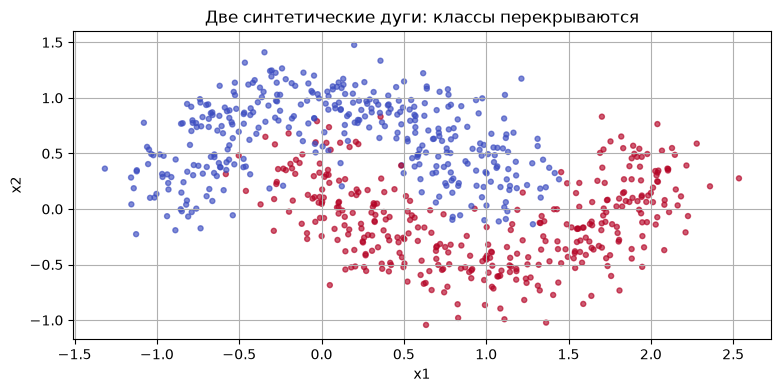

In [2]:
df = pd.read_csv(DATA / 'two_moons.csv')
assert df['sample_id'].is_unique and not df.isna().any().any()
assert set(df.target.unique()) == {0, 1}
display(df.describe().round(3))
fig, ax = plt.subplots()
ax.scatter(df.x1, df.x2, c=df.target, cmap='coolwarm', s=13, alpha=.65)
ax.set(xlabel='x1', ylabel='x2', title='Две синтетические дуги: классы перекрываются')
plt.show()


## 2. Train / validation / test

Разделим 60% / 20% / 20%. Только train определяет масштабирование и веса; validation выбирает гиперпараметры. Test откроем после выбора. Stratify сохраняет доли классов, но не заменяет временное/групповое разделение в реальном проекте.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, log_loss, ConfusionMatrixDisplay
train, rest = train_test_split(df, test_size=.4, stratify=df.target, random_state=SEED)
valid, test = train_test_split(rest, test_size=.5, stratify=rest.target, random_state=SEED)
scaler = StandardScaler().fit(train[['x1', 'x2']])
Xtr, Xva, Xte = [scaler.transform(d[['x1', 'x2']]) for d in (train, valid, test)]
ytr, yva, yte = [d.target.to_numpy() for d in (train, valid, test)]
assert not (set(train.sample_id) & set(test.sample_id))
assert not (set(train.sample_id) & set(valid.sample_id))
assert np.allclose(Xtr.mean(axis=0), 0, atol=1e-10)
display(pd.Series({'train': len(train), 'validation': len(valid), 'test': len(test)}))


train         432
validation    144
test          144
dtype: int64

## 3. Loss и регуляризация

      Binary cross-entropy: $L=-\frac1n\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]$.
      L2-штраф сдерживает большие веса. Сравним `alpha`, оставив архитектуру и seed одинаковыми.
      `partial_fit` делает один проход по train; мы отдельно сохраняем внешний validation loss.
      Это учебный MLP с двумя скрытыми слоями, а не языковая модель.


In [4]:
from copy import deepcopy
def train_candidate(alpha, epochs=75):
    model = MLPClassifier(hidden_layer_sizes=(32, 16), alpha=alpha,
                          batch_size=64, learning_rate_init=.01, random_state=SEED)
    history, best = [], None
    best_loss = np.inf
    for epoch in range(epochs):
        model.partial_fit(Xtr, ytr, classes=np.array([0, 1]))
        loss_tr = log_loss(ytr, model.predict_proba(Xtr))
        loss_va = log_loss(yva, model.predict_proba(Xva))
        history.append({'epoch': epoch + 1, 'train_loss': loss_tr, 'validation_loss': loss_va})
        if loss_va < best_loss:
            best_loss, best = loss_va, deepcopy(model)
    return best, pd.DataFrame(history)

candidates = {alpha: train_candidate(alpha) for alpha in [.0001, .05, 1.0]}
comparison = pd.DataFrame([{'alpha': a, 'best_validation_loss': h.validation_loss.min(),
                            'best_epoch': int(h.validation_loss.idxmin() + 1)}
                           for a, (_, h) in candidates.items()])
display(comparison.sort_values('best_validation_loss'))


,alpha,best_validation_loss,best_epoch
1,0.0500,0.151069,24
0,0.0001,0.155564,25
2,1.0000,0.215866,75


## 4. Чтение learning curves

Падение train loss при росте validation loss — сигнал переобучения. Разрыв зависит и от размера выборки, шума и регуляризации. Выберите модель до просмотра test; не обещаем, что самое большое `alpha` всегда лучше.


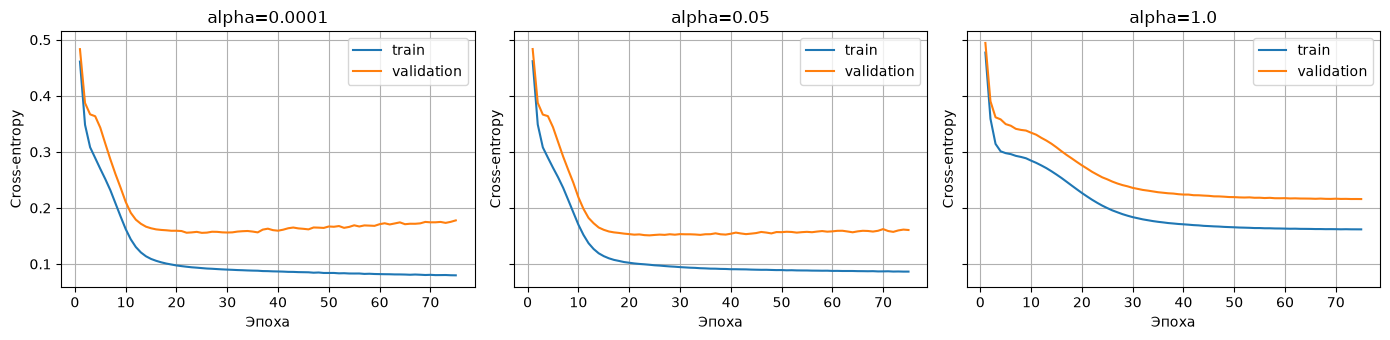

Выбор по validation: 0.05


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (alpha, (_, history)) in zip(axes, candidates.items()):
    ax.plot(history.epoch, history.train_loss, label='train')
    ax.plot(history.epoch, history.validation_loss, label='validation')
    ax.set(title=f'alpha={alpha}', xlabel='Эпоха', ylabel='Cross-entropy')
    ax.legend()
plt.tight_layout(); plt.show()
chosen_alpha = float(comparison.loc[comparison.best_validation_loss.idxmin(), 'alpha'])
chosen = candidates[chosen_alpha][0]
print('Выбор по validation:', chosen_alpha)


## 5. Однократная итоговая оценка

В реальном эксперименте test-метрику не используют для дальнейшего выбора. Здесь confusion matrix показывает тип ошибок. Accuracy на искусственных данных не оценивает качество на реальных задачах.


test_accuracy    0.937500
test_log_loss    0.118182
dtype: float64

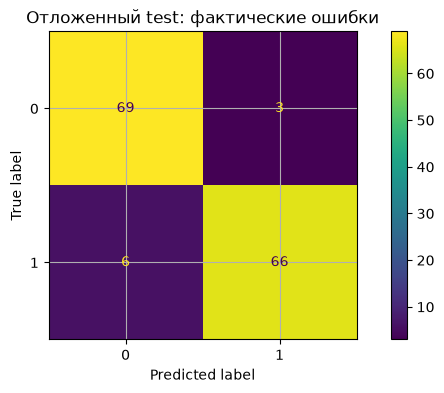

In [6]:
predicted = chosen.predict(Xte)
display(pd.Series({'test_accuracy': accuracy_score(yte, predicted),
                   'test_log_loss': log_loss(yte, chosen.predict_proba(Xte))}))
assert chosen.predict_proba(Xte).shape == (len(test), 2)
assert np.allclose(chosen.predict_proba(Xte).sum(axis=1), 1)
ConfusionMatrixDisplay.from_predictions(yte, predicted)
plt.title('Отложенный test: фактические ошибки'); plt.show()


## 6. Проверка воспроизводимости

Повторим выбранный эксперимент с тем же seed и сравним вероятности. Совпадение в этом окружении не гарантирует побитовую идентичность на любых версиях библиотек и BLAS.


In [7]:
repeated, _ = train_candidate(chosen_alpha)
assert np.allclose(chosen.predict_proba(Xva), repeated.predict_proba(Xva), atol=1e-9)
print('Одинаковый seed воспроизводит validation probabilities в этом окружении.')


Одинаковый seed воспроизводит validation probabilities в этом окружении.


## 7. От слов к токенам

В учебном корпусе делим по пробелам, чтобы видеть индексы. Реальные LLM используют специальные токенизаторы и часто разбивают слово на части. Слово, символ и токен — разные единицы; количество слов не равно API token usage.


In [8]:
lines = (DATA / 'tiny_corpus.txt').read_text(encoding='utf-8').splitlines()
words = ' '.join(lines).split()
vocabulary = {word: i for i, word in enumerate(sorted(set(words)))}
encoded = [vocabulary[word] for word in lines[0].split()]
display(pd.DataFrame({'word': list(vocabulary), 'token_id': list(vocabulary.values())}))
print(lines[0], '→', encoded)
assert len(encoded) == 3


,word,token_id
0,данные,0
1,задачу,1
2,изучает,2
3,класс,3
4,модель,4
5,обучает,5
6,описывают,6
7,предсказывает,7
8,студент,8


студент изучает данные → [8, 2, 0]


## 8. Один attention-head на NumPy

      $Q=XW_Q$, $K=XW_K$, $V=XW_V$; $A=\operatorname{softmax}(QK^T/\sqrt{d_k}+M)$,
      выход $AV$. В causal mask будущие позиции получают $-\infty$.
      Здесь матрицы случайные, не обученные; картинка объясняет вычисления, а не «что поняла LLM».


In [9]:
token_labels = lines[0].split()
n, d = len(encoded), 4
embeddings = rng.normal(0, .5, (len(vocabulary), d))
X = embeddings[encoded]
Q, K, V = [X @ rng.normal(0, .4, (d, d)) for _ in range(3)]
scores = Q @ K.T / np.sqrt(d)
mask = np.triu(np.ones((n, n), dtype=bool), k=1)
scores[mask] = -np.inf
def softmax(matrix):
    exp = np.exp(matrix - matrix.max(axis=-1, keepdims=True))
    return exp / exp.sum(axis=-1, keepdims=True)
attention = softmax(scores)
output = attention @ V
assert np.allclose(attention.sum(axis=1), 1)
assert np.all(attention[mask] == 0) and output.shape == (n, d)
display(pd.DataFrame(attention, index=token_labels, columns=token_labels).round(3))


,студент,изучает,данные
студент,1.000,0.000,0.000
изучает,0.248,0.752,0.000
данные,0.218,0.446,0.336


## 9. Визуализация causal attention

Строка — позиция, которая запрашивает контекст; столбец — позиция, на которую она смотрит. Первый токен видит только себя. В полноценной модели добавляют позиционную информацию, несколько heads, residual-связи, нормализацию и feed-forward блоки.


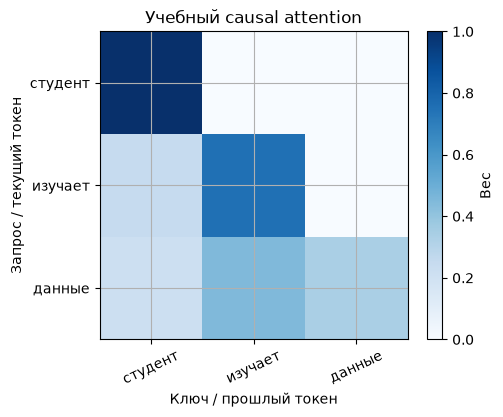

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(attention, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(n), token_labels, rotation=25)
ax.set_yticks(range(n), token_labels)
ax.set(xlabel='Ключ / прошлый токен', ylabel='Запрос / текущий токен', title='Учебный causal attention')
fig.colorbar(im, ax=ax, label='Вес'); plt.show()


## 10. Проверяемое объяснение и структура промпта

Промпт задает цель, данные, ограничения и формат результата. Просим краткое обоснование с проверяемым вычислением, а не раскрытие скрытого внутреннего рассуждения модели.


In [11]:
prompt = {'task': 'Сравни train и validation loss.',
          'data': comparison.round(4).to_dict('records'),
          'constraints': 'Выбирай только по validation; не используй test для подбора.',
          'output': 'alpha, 2 предложения обоснования, одно ограничение'}
print(json.dumps(prompt, ensure_ascii=False, indent=2))


{
  "task": "Сравни train и validation loss.",
  "data": [
    {
      "alpha": 0.0001,
      "best_validation_loss": 0.1556,
      "best_epoch": 25
    },
    {
      "alpha": 0.05,
      "best_validation_loss": 0.1511,
      "best_epoch": 24
    },
    {
      "alpha": 1.0,
      "best_validation_loss": 0.2159,
      "best_epoch": 75
    }
  ],
  "constraints": "Выбирай только по validation; не используй test для подбора.",
  "output": "alpha, 2 предложения обоснования, одно ограничение"
}


## Источники и следующий шаг

- [scikit-learn: MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)
- [Stanford CS224N: course materials](https://web.stanford.edu/class/cs224n/)
- [Attention Is All You Need, original paper](https://arxiv.org/abs/1706.03762)

Откройте Markdown-задание в папке `../homework/` своей недели. Перед сдачей перезапустите ядро и убедитесь, что выводы соответствуют фактическим результатам.
